# Distortion, lateral colour and lens shading correction

Notebook [160 (image restoration and PSF deconvolution)](160_image_restoration_deconvolution.ipynb)
undid the *blur* of the phone lens of notebook
[159 (phone camera lens with Forbes Q polynomials)](159_phone_camera_lens_forbes_q.ipynb).
Its PSFs were centred on the chief ray, so the restored image was still
distorted, still had the colour fringes of lateral colour, and was still
darker and coloured in the corners. These are the *geometric* and
*radiometric* errors of the lens. Unlike the blur, they lose no
information. Every camera corrects them, in the image signal processor
(ISP), with maps that come from the lens design and a calibration of each
module.

This notebook derives those maps from the traced lens and tries them out:

1. **Distortion.** The mapping from field angle to image height, its
   polynomial model, and the warp that makes straight lines straight
   (notebook [50 (magnification, distortion and telecentricity)](50_magnification_distortion_telecentricity.ipynb)
   for the basics).
2. **Lateral colour.** A warp per colour channel, and what it cannot
   remove.
3. **The cost of resampling** and the **order of the operations**: warp
   first and restore after, or the other way round?
4. **Lens shading.** Relative illumination of the lens (notebook
   [106 (radiometry of images)](106_radiometry_of_images.ipynb)), the
   acceptance of the pixels at the chief ray angle with and without a
   microlens shift (notebook [93 (the sensor)](93_sensor.ipynb)), and the
   *colour shading* that the IR cut filter adds at oblique incidence.
5. **Lens shading correction** with the gain tables of an ISP, its noise
   cost, and the whole chain from the raw mosaic to a corrected picture.

### How it is done in practice

- **Distortion** is modelled either with a polynomial in the radius, the
  Brown–Conrady model $r_d = r(1 + k_1 r^2 + k_2 r^4 + k_3 r^6)$ plus
  tangential terms for decentred modules (Brown 1966, Conrady 1919), as in
  OpenCV and the camera calibration of Zhang (2000), or with a look up
  table of the radial mapping. Photographic raw converters use the
  manufacturer's tables or lens profiles (Adobe DNG `WarpRectilinear`
  with a radial polynomial per colour plane, lensfun). The correction is
  an *inverse* mapping: for every pixel of the output, find where it lies
  on the sensor and interpolate there.
- **Lateral colour** is a radial scale per channel. The DNG opcode has one
  polynomial per colour plane for that reason. ISPs often take G as the
  reference and warp R and B onto it.
- **Lens shading correction (LSC)** multiplies the raw image with a gain
  per colour channel that is stored on a coarse grid, for example
  13 × 17 or 17 × 13 nodes, and interpolated bilinearly. It is one of the
  first blocks of the ISP, on the raw Bayer data, before white balance
  and demosaicing. The tables are calibrated per module with a flat field
  and often per illuminant (the colour shading depends on the spectrum of
  the light), and blended with the white balance estimate. Some ISPs keep
  part of the brightness fall-off in the corners on purpose to limit the
  noise gain.
- **Order.** In a typical ISP: black level, LSC, white balance,
  demosaicing, colour correction, denoising and sharpening, and the
  geometric warp near the end, often merged with the crop, the scaling and
  electronic image stabilization into a single resampling.

The new module `lens_correction` holds the radial mappings, the warps,
the shading model and the gain tables.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import phone_lens as pl
from pyoptics import lens_correction as lc
from pyoptics import restoration as rs
from pyoptics import sensor as se
from pyoptics import colour
from pyoptics.processing import CameraNoiser

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.grid": True, "grid.color": "0.88", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
CH, CCOL = ("R", "G", "B"), (RED, GREEN, BLUE)
t_start = time.time()

lens = pl.phone_lens()
PITCH = 1.0e-3                         # pixel pitch (mm)
H = pl.IMAGE_HEIGHT                    # half diagonal (mm)
SX, SY = 0.8*H, 0.6*H                  # half width and height of the 4:3 sensor
WL_NM = np.arange(430, 671, 20)
WL = WL_NM*1e-6
SENS = rs.cfa_sensitivity(WL_NM)       # R, G, B with the IR cut filter at normal incidence
TH = np.linspace(0, lens.max_field, 121)
h_wl, ideal = lc.radial_mapping(lens, TH, WL)
h_ch = lc.channel_heights(h_wl, SENS)
h_fdc, _ = lc.radial_mapping(lens, TH, pl.WAVELENGTHS)
print("f = {:.3f} mm, half field {:.2f}°, image height {:.3f} mm (G) for {:.3f} mm rectilinear".format(
    lens.paraxial().efl, np.degrees(lens.max_field), h_ch[1, -1], ideal[-1]))
print("the sensor sits {:.1f} µm behind the paraxial focus".format(1e3*(lens.surfaces[-1].thickness - lens.paraxial().bfl)))

f = 4.000 mm, half field 36.87°, image height 3.048 mm (G) for 3.000 mm rectilinear
the sensor sits 25.6 µm behind the paraxial focus


The first numbers already show the scale. The image height of the full
field is 3.048 mm instead of $f \tan\theta = 3.000$ mm: the lens has about
1.6 % of pincushion at the corner, and much more on the way there.

## 1. Distortion

The traced chief ray heights against the rectilinear $f \tan\theta$ give
the distortion. It is *wavy*: it rises to 3.5 % at 0.32 field, falls to
1.8 % at 0.5, and oscillates between 1.4 and 2.5 % out to the corner.
This is what a lens with high order aspheres looks like when distortion is
only one of many terms in the merit function. It does not go to 0 on the
axis either, because the sensor sits 25.6 µm behind the paraxial focus,
where the image is sharpest over the field. The chief rays leave the lens
at an angle, so the image grows by about 1 % against the paraxial one.
That is only a scale and does not matter for the correction.

On the sensor this means displacements of up to 67 pixels near the corner.
The three wavelengths have nearly the same distortion; the difference
between them is the lateral colour of section 2.

largest distortion 3.46 % at 0.32 field; largest displacement 67 pixels at 0.96 field


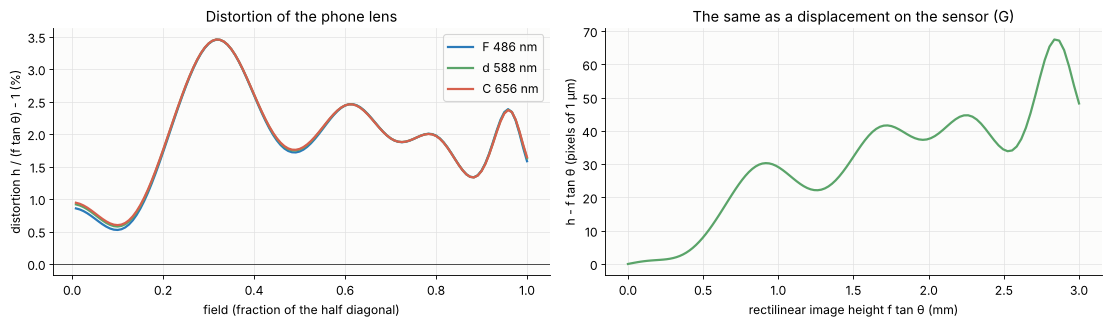

In [2]:
fr = TH/lens.max_field
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
with np.errstate(invalid="ignore", divide="ignore"):
    for k, (lab, col) in enumerate(zip(("F 486 nm", "d 588 nm", "C 656 nm"), (BLUE, GREEN, RED))):
        axes[0].plot(fr, 100*(h_fdc[k]/ideal - 1), color=col, lw=2, label=lab)
axes[0].axhline(0, color="k", lw=0.6)
axes[0].set_xlabel("field (fraction of the half diagonal)")
axes[0].set_ylabel("distortion h / (f tan θ) - 1 (%)")
axes[0].set_title("Distortion of the phone lens")
axes[0].legend()
axes[1].plot(ideal, (h_ch[1] - ideal)/PITCH, color=GREEN, lw=2)
axes[1].set_xlabel("rectilinear image height f tan θ (mm)")
axes[1].set_ylabel("h - f tan θ (pixels of 1 µm)")
axes[1].set_title("The same as a displacement on the sensor (G)")
fig.tight_layout()
k = np.nanargmax(np.abs(h_ch[1, 1:]/ideal[1:] - 1)) + 1
print("largest distortion {:.2f} % at {:.2f} field; largest displacement {:.0f} pixels at {:.2f} field".format(
    100*(h_ch[1, k]/ideal[k] - 1), fr[k], np.max(np.abs(h_ch[1] - ideal))/PITCH,
    fr[np.argmax(np.abs(h_ch[1] - ideal))]))

The usual polynomial model does not fit this lens. One term leaves
residuals of 33 pixels, three terms (the OpenCV default) 28 pixels, and
even six terms still 9 pixels, with the residuals oscillating. A smooth lens with a monotonic distortion is
described by two or three terms to a fraction of a pixel; a modern phone
lens with its wavy distortion needs a look up table of the radial
mapping, or a polynomial of a much higher degree. Everything below uses
the traced mapping directly.

radial terms   k_1 ...                                       largest residual (pixels)
     1         +0.027                                         33.02
     2         +0.073 -0.059                                  24.88
     3         +0.165 -0.351 +0.212                           27.71
     4         +0.276 -0.980 +1.266 -0.544                    15.46
     6         +0.629 -5.165 +18.543 -32.846 ...               9.07


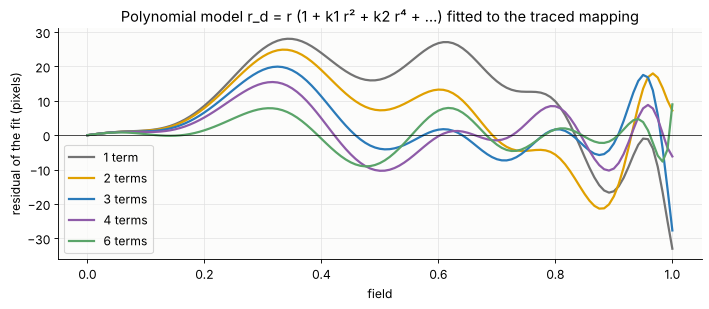

In [3]:
rn = ideal/ideal[-1]                   # normalized radii
fig, ax = plt.subplots(figsize=(9, 4))
print("radial terms   k_1 ...                                       largest residual (pixels)")
for n_terms, col in zip((1, 2, 3, 4, 6), (GREY, ORANGE, BLUE, PURPLE, GREEN)):
    kk, res = lc.fit_brown_radial(rn, h_ch[1]/ideal[-1], n_terms)
    ax.plot(fr, res*ideal[-1]/PITCH, color=col, lw=2, label="{} term{}".format(n_terms, "s"*(n_terms > 1)))
    print("{:6d}         {:44s} {:7.2f}".format(n_terms, " ".join("{:+.3f}".format(v) for v in kk[:4])
                                                  + (" ..." if n_terms > 4 else ""), np.max(np.abs(res))*ideal[-1]/PITCH))
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("field")
ax.set_ylabel("residual of the fit (pixels)")
ax.set_title("Polynomial model r_d = r (1 + k1 r² + k2 r⁴ + ...) fitted to the traced mapping")
ax.legend()
fig.tight_layout()

The warp map shows the waviness as rings: the displacement goes up and
down five times from the centre to the corner. Straight lines of the scene
are waves on the sensor, with amplitudes of 5 to 15 pixels. A wavy
distortion is more visible than a smooth one of the same size, because
the eye picks up the curvature, not the displacement.

The pitch of the corrected image is chosen so that its corners fall on
the corners of the sensor. With a pincushion distortion the edges of the
sensor then bow inwards, so the corrected image loses a sliver of the
field at the middle of the edges, and the frame covers 1.9 % less of the
diagonal field than the sensor does. ISPs crop that away.

corrected image: pitch 0.9807 µm-equivalent, it covers 1.93 % less field than the sensor diagonal


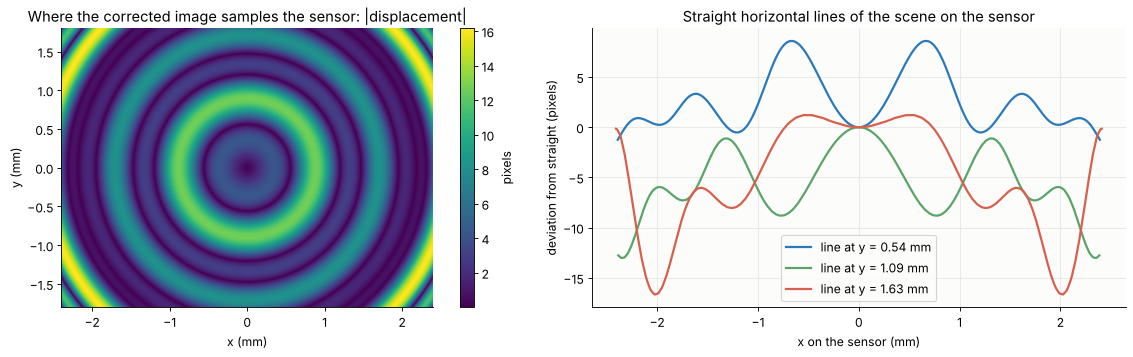

In [4]:
DS = 10                                 # coarse grid: one sample per 10 pixels
ny, nx = int(2*SY/PITCH)//DS, int(2*SX/PITCH)//DS
r_corner = np.interp(H, h_ch[1], ideal)  # rectilinear radius imaged onto the sensor corner
OUT = PITCH*r_corner/H                   # pitch of the corrected image: its corners stay on the sensor
rows, cols = lc.warp_coordinates((ny, nx), PITCH*DS, ideal, h_ch[1], out_pitch=OUT*DS)
yy, xx = np.indices((ny, nx))
disp = np.hypot(rows - yy, cols - xx)*DS          # in sensor pixels
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
im = axes[0].imshow(disp, origin="lower", cmap="viridis", extent=[-SX, SX, -SY, SY])
fig.colorbar(im, ax=axes[0], label="pixels")
axes[0].set_title("Where the corrected image samples the sensor: |displacement|")
axes[0].set_xlabel("x (mm)"); axes[0].set_ylabel("y (mm)"); axes[0].grid(False)
# straight lines of the scene as the sensor sees them
for yl, col in ((0.3*SY, BLUE), (0.6*SY, GREEN), (0.9*SY, RED)):
    x = np.linspace(-SX, SX, 400)*r_corner/H
    r = np.hypot(x, yl*r_corner/H)
    m = np.interp(r, ideal, h_ch[1])/r
    xs, ys = x*m, yl*r_corner/H*m
    axes[1].plot(xs, (ys - ys[len(ys)//2])/PITCH, color=col, lw=2, label="line at y = {:.2f} mm".format(ys[len(ys)//2]))
axes[1].set_xlabel("x on the sensor (mm)")
axes[1].set_ylabel("deviation from straight (pixels)")
axes[1].set_title("Straight horizontal lines of the scene on the sensor")
axes[1].legend()
fig.tight_layout()
print("corrected image: pitch {:.4f} µm-equivalent, it covers {:.2f} % less field than the sensor diagonal".format(
    OUT*1e3, 100*(1 - r_corner/ideal[-1])))

## 2. Lateral colour

The channel image heights are the chief ray heights averaged over the
sensitivity of each channel. R and B differ from G by less than a pixel
over most of the field, with up to 0.7 pixels for R and 1.1 for B at the
corner; across the whole band, 430 to 670 nm, it is 3 pixels at the
corner. That is small: the lens is well corrected for colour, as the
nearly equal channel PSFs of notebook
[160 (image restoration and PSF deconvolution)](160_image_restoration_deconvolution.ipynb)
showed already.

A warp per channel removes the *mean* shift of each channel. What remains
is the spread of the wavelengths *within* a channel (right): up to
0.56 pixels rms at the corner. This part is a colour smear, not a shift,
and only a deconvolution with the channel PSF, or nothing, can deal with
it.

largest R - G: 0.72 px, B - G: 1.12 px; largest spread within a channel: 0.56 px


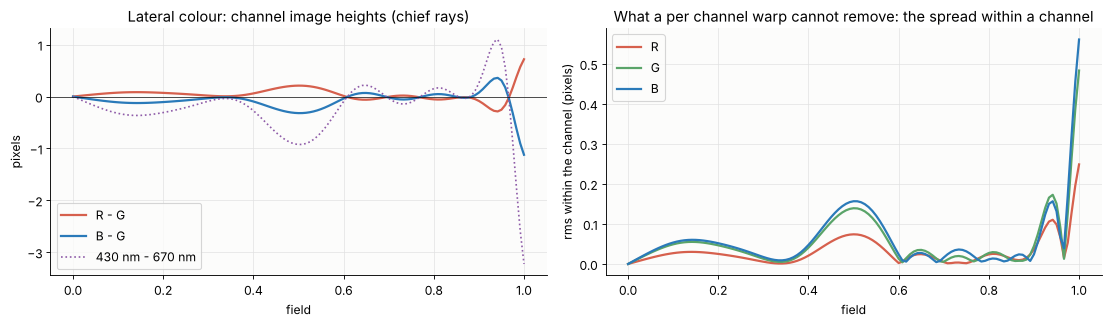

In [5]:
spread = []
for ch in range(3):
    w = SENS[ch]/SENS[ch].sum()
    spread.append(np.sqrt(w @ (h_wl - h_ch[ch])**2))
spread = np.array(spread)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(fr, (h_ch[0] - h_ch[1])/PITCH, color=RED, lw=2, label="R - G")
axes[0].plot(fr, (h_ch[2] - h_ch[1])/PITCH, color=BLUE, lw=2, label="B - G")
axes[0].plot(fr, (h_wl[0] - h_wl[-1])/PITCH, ":", color=PURPLE, lw=1.5, label="430 nm - 670 nm")
axes[0].axhline(0, color="k", lw=0.6)
axes[0].set_xlabel("field"); axes[0].set_ylabel("pixels")
axes[0].set_title("Lateral colour: channel image heights (chief rays)")
axes[0].legend()
for ch in range(3):
    axes[1].plot(fr, spread[ch]/PITCH, color=CCOL[ch], lw=2, label=CH[ch])
axes[1].set_xlabel("field"); axes[1].set_ylabel("rms within the channel (pixels)")
axes[1].set_title("What a per channel warp cannot remove: the spread within a channel")
axes[1].legend()
fig.tight_layout()
print("largest R - G: {:.2f} px, B - G: {:.2f} px; largest spread within a channel: {:.2f} px".format(
    np.max(np.abs(h_ch[0] - h_ch[1]))/PITCH, np.max(np.abs(h_ch[2] - h_ch[1]))/PITCH, spread.max()/PITCH))

A checkerboard imaged without blur at the corner of the sensor shows it.
The sensor image has fringes, blue on one side of the edges and orange on
the other. One warp for all channels makes the lines straight, but the
fringes stay. A warp per channel halves the colour error. The rest is the
smear within the channels.

one warp (G)  : rms R - G 0.0356, B - G 0.0434 (scene: 0)
per channel   : rms R - G 0.0182, B - G 0.0208 (scene: 0)


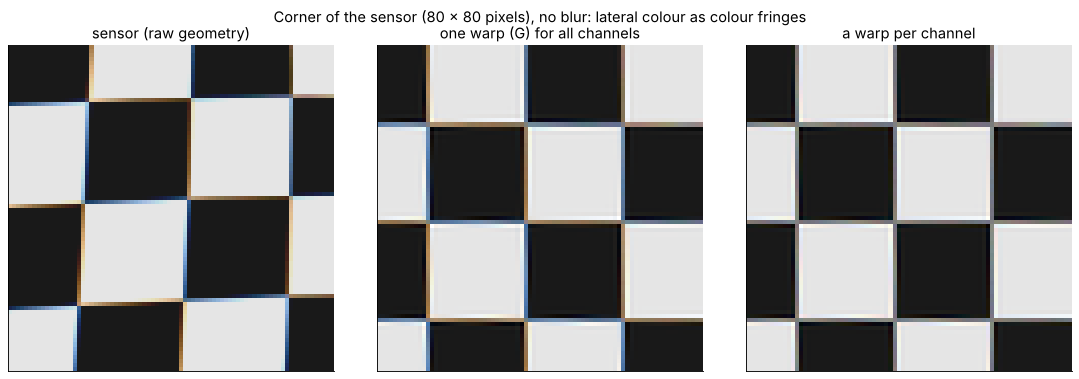

In [6]:
# a crop at the sensor corner, imaged without blur: each wavelength shifted by its own mapping
NC = 160
row0, col0 = int(round((SY + SY)/PITCH)) - NC - 40, int(round((SX + SX)/PITCH)) - NC - 40
centre = ((2*SY/PITCH - 1)/2 - row0, (2*SX/PITCH - 1)/2 - col0)   # the axis in crop pixels
OS = 4
t = (np.arange(NC*OS) + 0.5)/OS - 0.5
Ys, Xs = np.meshgrid(t, t, indexing="ij")


def chart(Y, X):
    """Black and white squares (24 px) and thin lines in rectilinear pixel coordinates."""
    sq = ((np.floor(X/24) + np.floor(Y/24)) % 2 == 0).astype(float)
    return 0.1 + 0.8*sq


# rectilinear coordinates (in output pixels) seen by a sensor point: invert each mapping
def sensor_channel(heights):
    rs_ = np.hypot((Ys - centre[0])*PITCH, (Xs - centre[1])*PITCH)
    ru = np.interp(rs_, heights, ideal)/ (OUT/PITCH)
    m = ru/rs_
    return chart(centre[0] + (Ys - centre[0])*m, centre[1] + (Xs - centre[1])*m)


raw_c = np.zeros((3, NC, NC))
for j in range(len(WL)):
    img = sensor_channel(h_wl[j]).reshape(NC, OS, NC, OS).mean(axis=(1, 3))
    raw_c += (SENS[:, j]/SENS.sum(axis=1))[:, None, None]*img[None]
rows_g, cols_g = lc.warp_coordinates((NC, NC), PITCH, ideal, h_ch[1], out_pitch=OUT, centre=centre)
only_g = lc.remap(raw_c, rows_g, cols_g, order=3)
per_ch = np.array([lc.remap(raw_c[ch], *lc.warp_coordinates((NC, NC), PITCH, ideal, h_ch[ch], out_pitch=OUT,
                                                             centre=centre), order=3) for ch in range(3)])
truth_c = chart(*np.meshgrid(np.arange(NC), np.arange(NC), indexing="ij"))
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
for a, (name, img) in zip(axes, (("sensor (raw geometry)", raw_c), ("one warp (G) for all channels", only_g),
                                  ("a warp per channel", per_ch))):
    a.imshow(np.clip(img, 0, 1).transpose(1, 2, 0)[60:140, 60:140], origin="lower", interpolation="nearest")
    a.set_title(name); a.set_xticks([]); a.set_yticks([]); a.grid(False)
fig.suptitle("Corner of the sensor (80 x 80 pixels), no blur: lateral colour as colour fringes")
fig.tight_layout()
for name, img in (("one warp (G)", only_g), ("per channel", per_ch)):
    print("{:14s}: rms R - G {:.4f}, B - G {:.4f} (scene: 0)".format(
        name, np.sqrt(np.mean((img[0] - img[1])[20:-20, 20:-20]**2)), np.sqrt(np.mean((img[2] - img[1])[20:-20, 20:-20]**2))))

## 3. The cost of resampling

The warp interpolates the image at positions between the pixels, and an
interpolation is a low pass filter whose strength changes with the sub
pixel position (right). For white noise, cubic splines keep three
quarters of the variance and pass 0.9 at a quarter of the sampling
frequency; bilinear interpolation keeps less than half of the variance,
smooths the image visibly, and makes the noise correlated. Nearest
neighbour keeps everything but moves edges by up to half a pixel. The
warp should come once, with a good kernel, and should be merged with any
other resampling (crop, scaling, stabilization).

The filtering also matters for what comes after the warp: the noise is
no longer white and no longer independent between neighbours, which
denoisers and deconvolution assume.

order   noise variance after the warp   transfer at 0.25 / 0.5 cycles per pixel
 0 nearest      0.995                          0.97 / 1.04
 1 bilinear     0.445                          0.67 / 0.49
 3 cubic spline    0.762                          0.92 / 0.68


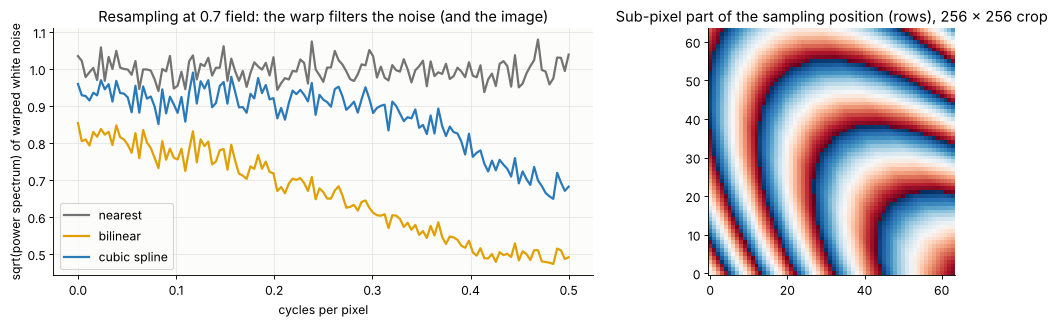

In [7]:
rng = np.random.default_rng(1)
noise = rng.standard_normal((256, 256))
c0 = ((2*SY/PITCH - 1)/2 - (0.7*SY/PITCH - 128), (2*SX/PITCH - 1)/2 - (0.7*SX/PITCH - 128))
rw, cw = lc.warp_coordinates((256, 256), PITCH, ideal, h_ch[1], out_pitch=OUT, centre=c0)
# the warp has a large offset at 0.7 field; resample a noise field that is periodic and large enough
big = rng.standard_normal((1024, 1024))
off_r, off_c = np.floor(rw.min()) - 8, np.floor(cw.min()) - 8
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
f = np.fft.rfftfreq(256)
print("order   noise variance after the warp   transfer at 0.25 / 0.5 cycles per pixel")
for order, col, lab in ((0, GREY, "nearest"), (1, ORANGE, "bilinear"), (3, BLUE, "cubic spline")):
    src = big[int(off_r) % 512:int(off_r) % 512 + 512, int(off_c) % 512:int(off_c) % 512 + 512]
    out = lc.remap(src, rw - off_r, cw - off_c, order=order)
    P = np.mean(np.abs(np.fft.rfft(out, axis=1))**2, axis=0)/256
    T = np.sqrt(P/1.0)
    axes[0].plot(f, T, color=col, lw=2, label=lab)
    print("{:2d} {:9s} {:8.3f}                          {:.2f} / {:.2f}".format(
        order, lab, out.var(), np.interp(0.25, f, T), np.interp(0.5, f, T)))
axes[0].set_xlabel("cycles per pixel")
axes[0].set_ylabel("sqrt(power spectrum) of warped white noise")
axes[0].set_title("Resampling at 0.7 field: the warp filters the noise (and the image)")
axes[0].legend()
axes[1].imshow((rw - np.round(rw))[::4, ::4], origin="lower", cmap="RdBu", vmin=-0.5, vmax=0.5)
axes[1].set_title("Sub-pixel part of the sampling position (rows), 256 x 256 crop")
axes[1].grid(False)
fig.tight_layout()

### Warp first or restore first?

Distortion correction feels like the first step, but the deconvolution
needs the PSF in the same geometry as the image. On the sensor, the PSF is
what the atlas of notebook
[160 (image restoration and PSF deconvolution)](160_image_restoration_deconvolution.ipynb)
computed and the noise is white. After the warp, the PSF is stretched by
the local magnification of the mapping and the noise is filtered. To find
out how much this matters, a 256 × 256 pixel crop at 0.7 field is imaged
through the distortion and the G PSF, with photon and read noise, and
corrected in both orders.

In [8]:
psf, _ = rs.psf_samples(lens, [(0.7*SX, 0.7*SY)], WL, PITCH, n_pix=31)
psfG = rs.channel_psfs(psf, WL_NM)[0, 1]
N1 = 256
OS2 = 2
row1, col1 = int(round(SY/PITCH + 0.7*SY/PITCH)) - N1//2, int(round(SX/PITCH + 0.7*SX/PITCH)) - N1//2
cen1 = ((2*SY/PITCH - 1)/2 - row1, (2*SX/PITCH - 1)/2 - col1)
# the scene lives in rectilinear coordinates; the sensor sees it through the mapping of G
M = 40
rw1, cw1 = lc.warp_coordinates((N1, N1), PITCH, ideal, h_ch[1], out_pitch=OUT, centre=cen1)
r_lo, c_lo = int(np.floor(rw1.min())) - M, int(np.floor(cw1.min())) - M
n_scene = int(max(rw1.max() - r_lo, cw1.max() - c_lo)) + M
scene = rs.dead_leaves((n_scene, n_scene), r_min=1.5, r_max=100, rng=21)
# sensor pixel (i, j) of the crop shows the rectilinear point found by inverting the mapping
sub = (np.arange(N1*OS2) + 0.5)/OS2 - 0.5
Si, Sj = np.meshgrid(sub, sub, indexing="ij")
ri = np.hypot((Si - cen1[0])*PITCH, (Sj - cen1[1])*PITCH)
mm = np.interp(ri, h_ch[1], ideal)/(OUT/PITCH)/ri
# rectilinear output pixel coordinates of those sensor points, in the frame of the warp target crop
Ui = cen1[0] + (Si - cen1[0])*mm
Uj = cen1[1] + (Sj - cen1[1])*mm
# the scene is defined on output pixels shifted by (r_lo, c_lo) so that it covers the whole crop
scene_at = lambda u, v: lc.remap(scene, u - (r_lo - row1*0) + M, v - (c_lo - col1*0) + M, order=1)
truth_sensor = scene_at(Ui, Uj).reshape(N1, OS2, N1, OS2).mean(axis=(1, 3))
op = rs.SpaceVariantBlur.invariant(psfG, (N1 - 2*M, N1 - 2*M), margin=M)
blur = np.pad(op.forward(truth_sensor), M, mode="edge")
peak = 1000.0
yG = CameraNoiser("camera", read_noise=2.0, rng=3)(np.clip(blur, 0, None)*peak)/peak
truth_out = scene_at(*np.meshgrid(np.arange(N1, dtype=float), np.arange(N1, dtype=float), indexing="ij"))
print("PSF of G at 0.7 field; sensor crop {} x {} pixels, local magnification of the mapping {:.4f} (radial) {:.4f} (tangential)".format(
    N1, N1, np.interp(0.7*H, h_ch[1], np.gradient(h_ch[1], ideal)), np.interp(0.7*H, h_ch[1], h_ch[1]/np.maximum(ideal, 1e-9))))

PSF of G at 0.7 field; sensor crop 256 x 256 pixels, local magnification of the mapping 1.0326 (radial) 1.0190 (tangential)


In [9]:
F2 = np.abs(np.fft.rfft2(truth_sensor - truth_sensor.mean()))**2/truth_sensor.size
fy, fx = np.fft.fftfreq(N1)[:, None], np.fft.rfftfreq(N1)[None, :]
frq = np.hypot(fx, fy)
sel = (frq > 0.02) & (frq < 0.45)
sl_, ic_ = np.polyfit(np.log(frq[sel]), np.log(F2[sel]), 1)
nsr = lambda q: (np.mean(yG)*peak + 4)/peak**2/(np.exp(ic_)*np.maximum(q, 0.5/N1)**sl_)
opA = rs.SpaceVariantBlur.invariant(psfG, (N1, N1))
pipelines = {
    "warp only": lambda y: lc.remap(y, rw1, cw1),
    "deconvolve (Wiener), then warp": lambda y: lc.remap(rs.wiener(y, psfG, nsr), rw1, cw1),
    "warp, then deconvolve (Wiener)": lambda y: rs.wiener(lc.remap(y, rw1, cw1), psfG, nsr),
    "deconvolve (RL 40), then warp": lambda y: lc.remap(rs.richardson_lucy(y + 0.004, opA, 40, background=0.004), rw1, cw1),
    "warp, then deconvolve (RL 40)": lambda y: rs.richardson_lucy(np.clip(lc.remap(y, rw1, cw1), 0, None) + 0.004, opA, 40,
                                                                  background=0.004),
}
B = 48
res_order = {}
print("pipeline                              PSNR in the corrected frame (dB)")
for name, fn in pipelines.items():
    res_order[name] = fn(yG)
    print("{:36s}  {:6.2f}".format(name, rs.psnr(res_order[name], truth_out, border=B)))

pipeline                              PSNR in the corrected frame (dB)
warp only                              16.47
deconvolve (Wiener), then warp         20.40
warp, then deconvolve (Wiener)         20.38
deconvolve (RL 40), then warp          19.66


warp, then deconvolve (RL 40)          19.65


Both orders give the same result to within 0.02 dB, for Wiener as well as
for Richardson–Lucy, and both gain about 4 dB over the warp alone. The
local magnification of the mapping at 0.7 field is only 1.03 radially and
1.02 tangentially, so the PSF hardly changes in the warp, and the cubic
spline barely touches the frequencies that the deconvolution restores.

So for this lens the order does not matter for the quality. It matters
for the bookkeeping: the PSFs are calibrated and stored in sensor
coordinates, LSC and demosaicing work on the raw mosaic, and the warp is
cheapest as the one resampling at the end. That is why ISPs warp last. A
lens with strong distortion, such as a fisheye or an ultra wide with
20 % or more, would change this: there the PSF in the corrected image is
stretched noticeably, and the warp has to come after the restoration, or
the PSFs have to be warped too.

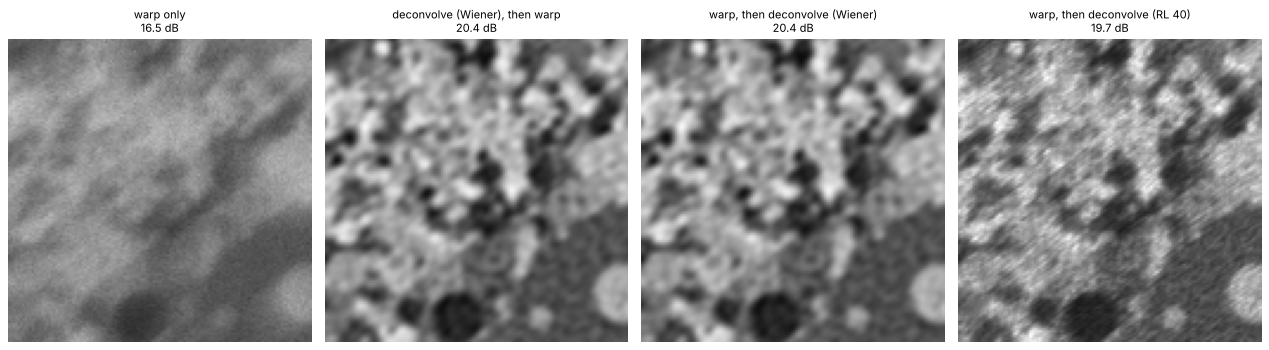

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.3))
for a, name in zip(axes, ["warp only", "deconvolve (Wiener), then warp", "warp, then deconvolve (Wiener)",
                          "warp, then deconvolve (RL 40)"]):
    a.imshow(res_order[name][B:B + 128, B:B + 128], cmap="gray", vmin=0, vmax=1, origin="lower")
    a.set_title("{}\n{:.1f} dB".format(name, rs.psnr(res_order[name], truth_out, border=B)), fontsize=10)
    a.axis("off")
fig.tight_layout()

## 4. Lens shading

### The lens: relative illumination and chief ray angle

The irradiance on the sensor falls to 0.79 at half field, 0.66 at 0.7
field and 0.47 at the corner: better than the cos⁴ law (0.41), as usual
for a phone lens with its large chief ray angles and pincushion
distortion. The curve is wavy, like the distortion: where the mapping
stretches the image, the light is spread over a larger area.

The chief ray angle on the sensor peaks at 31° near 0.65 field and falls
back to 18° at the corner. This non-monotonic CRA curve is typical of
compact phone lenses, whose last element bends the outer chief rays back
towards the axis.

relative illumination at 0.5 / 0.7 / 1.0 field: 0.79 / 0.66 / 0.47; cos^4: 0.41 at the corner
largest chief ray angle 30.9° at 0.65 field, 17.8° at the corner


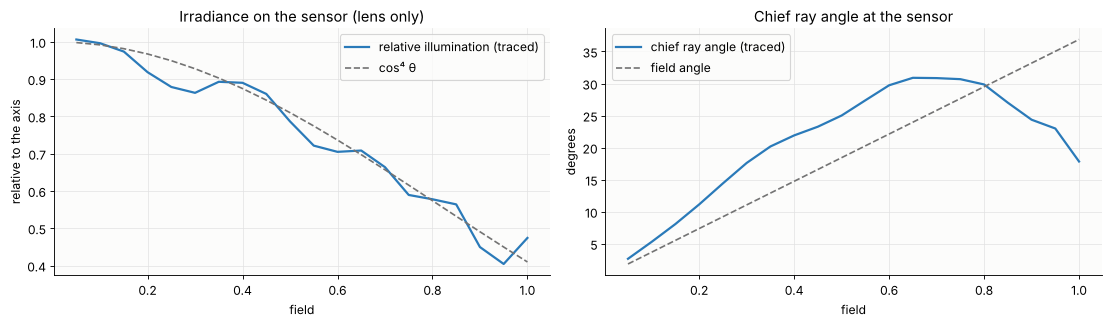

In [11]:
FS = np.linspace(0.05, 1.0, 20)*lens.max_field
cra = lc.chief_ray_angles(lens, FS)
lam = np.arange(400, 701, 5)
S_open = rs.cfa_sensitivity(lam, ir_cut=5000.0)    # dyes and silicon without the IR cut filter
IRC = dict(cut_nm=650.0, width_nm=10.0, n_eff=1.8)
stack = se.pixel_stack(pitch=PITCH)
sh_none, parts = lc.channel_shading(lens, FS, lam, S_open, n_rays=20000)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(FS/lens.max_field, parts["illumination"], color=BLUE, lw=2, label="relative illumination (traced)")
axes[0].plot(FS/lens.max_field, np.cos(FS)**4, "--", color=GREY, lw=1.5, label="cos⁴ θ")
axes[0].set_xlabel("field"); axes[0].set_ylabel("relative to the axis")
axes[0].set_title("Irradiance on the sensor (lens only)")
axes[0].legend()
axes[1].plot(FS/lens.max_field, np.degrees(cra), color=BLUE, lw=2, label="chief ray angle (traced)")
axes[1].plot(FS/lens.max_field, np.degrees(FS), "--", color=GREY, lw=1.5, label="field angle")
axes[1].set_xlabel("field"); axes[1].set_ylabel("degrees")
axes[1].set_title("Chief ray angle at the sensor")
axes[1].legend()
fig.tight_layout()
print("relative illumination at 0.5 / 0.7 / 1.0 field: {:.2f} / {:.2f} / {:.2f}; cos^4: {:.2f} at the corner".format(
    *np.interp([0.5, 0.7, 1.0], FS/lens.max_field, parts["illumination"]), np.cos(lens.max_field)**4))
print("largest chief ray angle {:.1f}° at {:.2f} field, {:.1f}° at the corner".format(
    np.degrees(cra.max()), FS[np.argmax(cra)]/lens.max_field, np.degrees(cra[-1])))

### The pixels

A 1 µm pixel has its microlens and colour filter above a photodiode a few
micrometres deep. At an oblique chief ray the spot of the microlens
wanders off the photodiode, and without a microlens shift almost no light
reaches the photodiode beyond half field. Sensors therefore shift the
microlenses towards the centre by an amount that grows with the image
height. A shift that is linear in the field and matched to the largest
CRA overcorrects the corner, where the CRA of this lens falls again. A
shift that follows the traced CRA keeps at least 63 % everywhere. The
sensor and the lens have to be designed together; this is why phone
camera sensors are specified for a CRA curve.

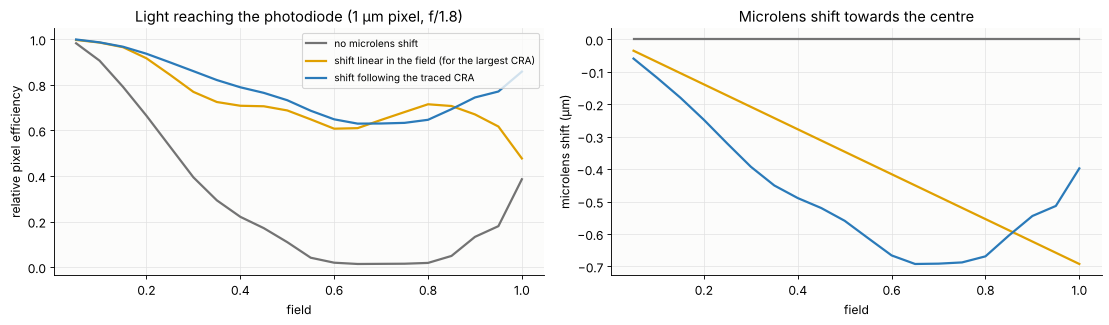

In [12]:
k_lin = se.microlens_shift(stack, cra.max())/np.interp(cra.max(), cra, FS)   # shift proportional to the field
designs = {"no microlens shift": np.zeros_like(cra),
           "shift linear in the field (for the largest CRA)": k_lin*FS,
           "shift following the traced CRA": np.array([se.microlens_shift(stack, c) for c in cra])}
eff = {}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for (name, sh), col in zip(designs.items(), (GREY, ORANGE, BLUE)):
    e = lc.pixel_efficiency(stack, cra, pl.F_NUMBER, sh, n_rays=10000)
    e0 = lc.pixel_efficiency(stack, [0.0], pl.F_NUMBER, n_rays=10000)[0]
    eff[name] = e/e0
    axes[0].plot(FS/lens.max_field, eff[name], color=col, lw=2, label=name)
    axes[1].plot(FS/lens.max_field, sh*1e3, color=col, lw=2, label=name)
axes[0].set_xlabel("field"); axes[0].set_ylabel("relative pixel efficiency")
axes[0].set_title("Light reaching the photodiode (1 µm pixel, f/1.8)")
axes[0].legend(fontsize=9)
axes[1].set_xlabel("field"); axes[1].set_ylabel("microlens shift (µm)")
axes[1].set_title("Microlens shift towards the centre")
fig.tight_layout()

### The IR cut filter and the colour shading

The IR cut filter is an interference filter, and its edge moves to
shorter wavelengths at oblique incidence, as
$\lambda_c(\theta) = \lambda_c(0) \sqrt{1 - \sin^2\theta/n_\mathrm{eff}^2}$.
The light arrives in a cone of f/1.8 around the chief ray, so the edge is
also smeared. At a chief ray angle of 30° it moves by about 25 nm and
cuts into the red channel.

The product of the three factors is the shading of each channel. G and B
follow each other closely. R falls further, to 0.69 of G at 0.65 field,
where the CRA is largest, and recovers to 0.89 at the corner. A grey wall
comes out cyan in a ring around the centre. This *colour shading* is what
LSC tables per channel are for, and why they depend on the light source:
a light with more red changes the share of R that the filter cuts.

at the corner: R 0.36, G 0.41, B 0.41; R/G 0.89, B/G 1.01; smallest R/G 0.69 at 0.65 field


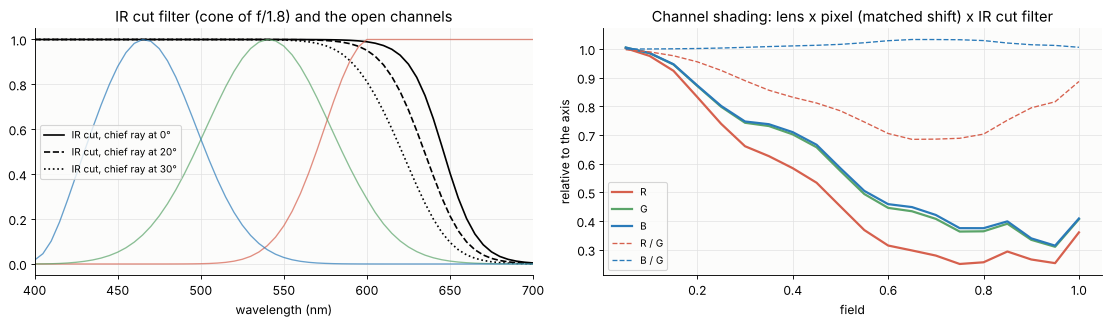

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
N_ = pl.F_NUMBER
for a_deg, ls in ((0, "-"), (20, "--"), (30, ":")):
    axes[0].plot(lam, lc.ir_cut_transmission(lam, lc.cone_angles(np.radians(a_deg), N_), **IRC), "k", ls=ls,
                 lw=1.5, label="IR cut, chief ray at {}°".format(a_deg))
for ch in range(3):
    axes[0].plot(lam, S_open[ch]/S_open[ch].max(), color=CCOL[ch], lw=1.2, alpha=0.7)
axes[0].set_xlim(400, 700)
axes[0].set_xlabel("wavelength (nm)"); axes[0].set_title("IR cut filter (cone of f/1.8) and the open channels")
axes[0].legend(fontsize=9)
matched = designs["shift following the traced CRA"]
sh_all, parts_all = lc.channel_shading(lens, FS, lam, S_open, stack=stack, shifts=matched, ir_cut=IRC, n_rays=20000)
for ch in range(3):
    axes[1].plot(FS/lens.max_field, sh_all[ch], color=CCOL[ch], lw=2, label=CH[ch])
axes[1].plot(FS/lens.max_field, sh_all[0]/sh_all[1], "--", color=RED, lw=1.2, label="R / G")
axes[1].plot(FS/lens.max_field, sh_all[2]/sh_all[1], "--", color=BLUE, lw=1.2, label="B / G")
axes[1].set_xlabel("field"); axes[1].set_ylabel("relative to the axis")
axes[1].set_title("Channel shading: lens x pixel (matched shift) x IR cut filter")
axes[1].legend(fontsize=9)
fig.tight_layout()
print("at the corner: R {:.2f}, G {:.2f}, B {:.2f}; R/G {:.2f}, B/G {:.2f}; smallest R/G {:.2f} at {:.2f} field".format(
    *sh_all[:, -1], sh_all[0, -1]/sh_all[1, -1], sh_all[2, -1]/sh_all[1, -1], np.min(sh_all[0]/sh_all[1]),
    FS[np.argmin(sh_all[0]/sh_all[1])]/lens.max_field))

The same as a picture: a grey wall at mid grey, seen by the sensor, then
with the G gain applied to all channels, and the colour cast that remains,
amplified four times.

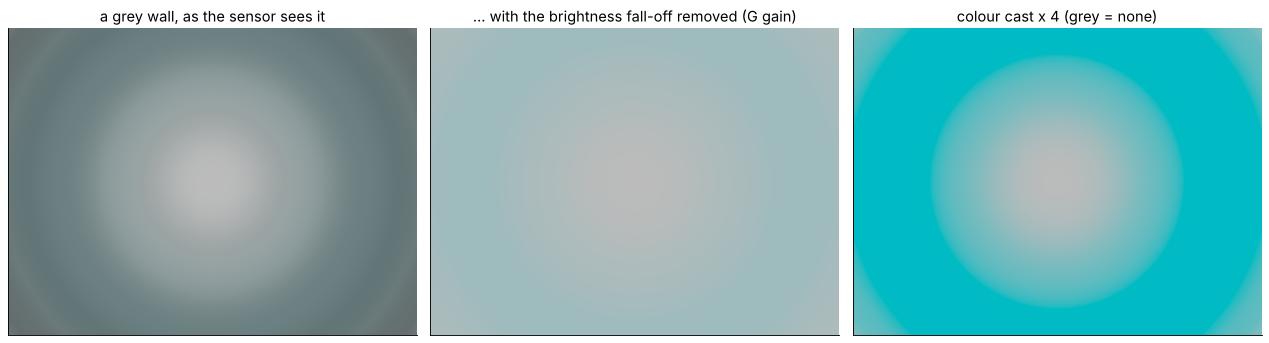

In [14]:
DS2 = 5                                       # a 960 x 720 picture of the full frame
shape2 = (int(2*SY/PITCH)//DS2, int(2*SX/PITCH)//DS2)
heights = np.concatenate([[0.0], np.interp(FS, TH, h_ch[1])])
S_map = lc.radial_map(shape2, PITCH*DS2, heights, np.concatenate([np.ones((3, 1)), sh_all], axis=1))
grey = 0.5*np.ones((3,) + shape2)


def show_rgb(ax, img, title):
    ax.imshow(colour.srgb_gamma(np.clip(img, 0, 1)).transpose(1, 2, 0), origin="lower", extent=[-SX, SX, -SY, SY])
    ax.set_title(title); ax.grid(False); ax.set_xticks([]); ax.set_yticks([])


fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
show_rgb(axes[0], grey*S_map, "a grey wall, as the sensor sees it")
wb = grey*S_map/S_map[:, shape2[0]//2, shape2[1]//2][:, None, None]
show_rgb(axes[1], grey*S_map/S_map[1:2], "... with the brightness fall-off removed (G gain)")
show_rgb(axes[2], 0.5 + 2.0*(S_map/S_map[1:2] - 1), "colour cast x 4 (grey = none)")
fig.tight_layout()

## 5. Lens shading correction

The gain is the inverse of the shading map. It is stored per channel on a
coarse grid and interpolated bilinearly. The table below gives the largest
error of the interpolated gain for grids from 5 × 7 to 33 × 45 nodes.

grid      largest error of the interpolated gain (R / G / B, %)
 5 x  7   23.70  17.94  17.81
 9 x 13   15.87  13.74  13.59


13 x 17   12.95  11.25  11.13
17 x 23    9.16   7.89   7.79
33 x 45    5.27   4.39   4.33


G gain only : corner R/G 0.852, B/G 1.019 (centre 1.000, 0.997)
per channel : corner R/G 1.004, B/G 1.009 (centre 1.003, 0.997)


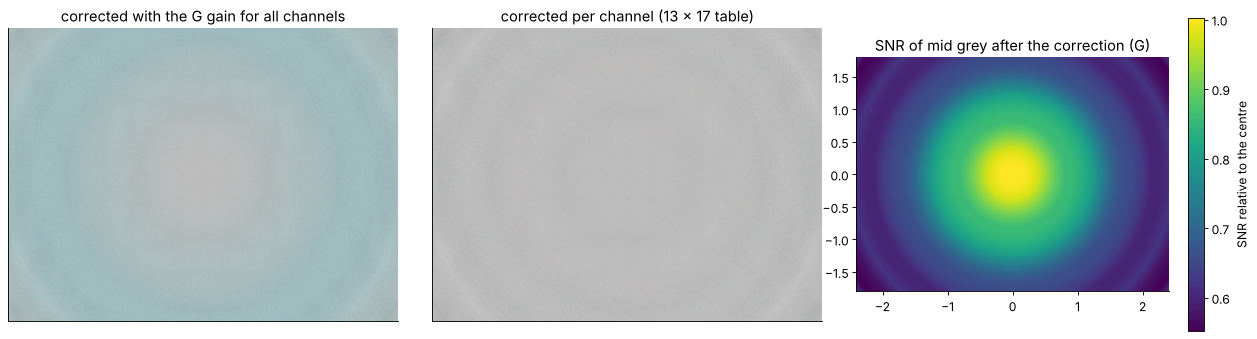

In [15]:
gain = 1/S_map
print("grid      largest error of the interpolated gain (R / G / B, %)")
tables = {}
for grid in ((5, 7), (9, 13), (13, 17), (17, 23), (33, 45)):
    tables[grid] = lc.gain_table(gain, grid)
    _, g = lc.apply_gain_table(np.ones(shape2), tables[grid])
    print("{:2d} x {:2d}   ".format(*grid) + "  ".join("{:5.2f}".format(100*np.max(np.abs(g[c]/gain[c] - 1)))
                                               for c in range(3)))
# a noisy flat field (white = 1000 e- on the axis), corrected per channel or with the G gain only
PEAK = 1000.0
flat = CameraNoiser("camera", read_noise=2.0, rng=7)(grey*S_map*PEAK)/PEAK
corr_ch, _ = lc.apply_gain_table(flat, tables[(13, 17)])
corr_g, _ = lc.apply_gain_table(flat, np.broadcast_to(tables[(13, 17)][1], (3,) + tables[(13, 17)].shape[1:]))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
show_rgb(axes[0], corr_g, "corrected with the G gain for all channels")
show_rgb(axes[1], corr_ch, "corrected per channel (13 x 17 table)")
snr = np.sqrt(S_map[1]*PEAK*0.5)/np.sqrt(S_map[1]*PEAK*0.5 + 4)*np.sqrt(S_map[1]*PEAK*0.5)
im = axes[2].imshow(snr/snr[shape2[0]//2, shape2[1]//2], origin="lower", cmap="viridis", extent=[-SX, SX, -SY, SY])
fig.colorbar(im, ax=axes[2], label="SNR relative to the centre")
axes[2].set_title("SNR of mid grey after the correction (G)"); axes[2].grid(False)
fig.tight_layout()
for name, img in (("G gain only", corr_g), ("per channel", corr_ch)):
    m = img.reshape(3, -1).mean(axis=1)
    corner = img[:, :20, :20].reshape(3, -1).mean(axis=1)
    print("{:12s}: corner R/G {:.3f}, B/G {:.3f} (centre {:.3f}, {:.3f})".format(
        name, corner[0]/corner[1], corner[2]/corner[1], img[0, 350:370, 470:490].mean()/img[1, 350:370, 470:490].mean(),
        img[2, 350:370, 470:490].mean()/img[1, 350:370, 470:490].mean()))

The common 13 × 17 table is not enough for this lens: its largest gain
error is 11 % in G and 13 % in R, and the correction leaves faint rings.
The errors sit where the shading curve has its kinks, near the corner,
where the illumination and the pixel efficiency both change quickly. A
smooth lens of the textbook kind would need far fewer nodes. With a wavy
design, the table has to be denser (33 × 45 nodes still leave 4 to 5 %),
or radial, as the distortion table.

The colour matters more than the brightness. With the G gain for all
channels the corner is still 15 % short in red. The per channel tables
bring R/G and B/G within 1 % everywhere.

The price is noise. The gain lifts the signal in the corner by a factor of
two to three, and the noise with it, so the SNR in the corner stays that
of the dark raw signal: about 60 % of the centre for mid grey. This is the
trade-off behind the partial LSC of many phones.

### The whole chain

A colour scene with a grid of straight lines, at a fifth of the
resolution (5 µm pixels for the whole 4.8 × 3.6 mm sensor), goes through
the distortion of each channel and the shading, is sampled by the Bayer
mosaic with noise at 1000 photo electrons for white, and is then corrected
as in an ISP: LSC on the raw mosaic with the 13 × 17 tables, Malvar
demosaicing, and a warp per channel.

raw, demosaiced    PSNR against the scene 10.02 dB
shading corrected  PSNR against the scene 16.69 dB
+ warp             PSNR against the scene 23.53 dB


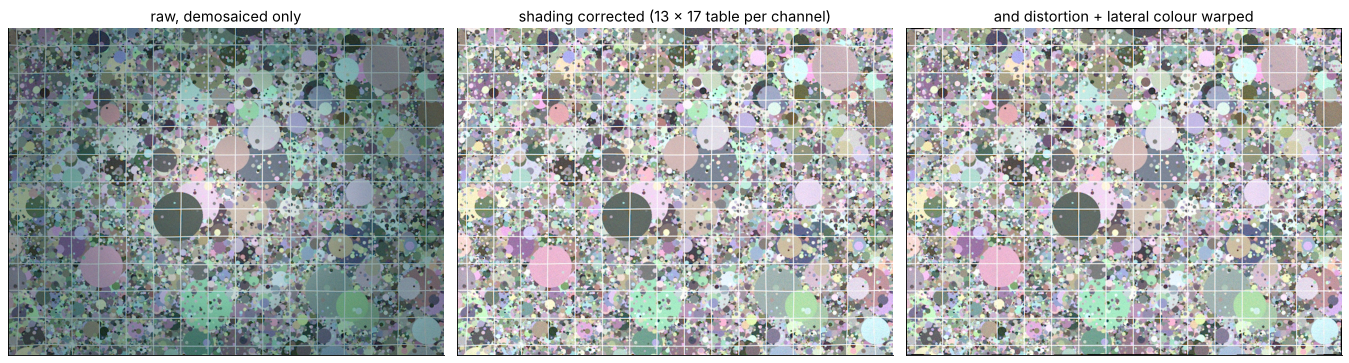

In [16]:
# a colour scene through the whole camera, at a fifth of the resolution
rng = np.random.default_rng(31)
cols = lambda g, n: np.clip(g.uniform(0.05, 0.9, (n, 1))*g.uniform(0.6, 1.4, (n, 3)), 0, 1)
Ny2, Nx2 = shape2
pad = 40
scene2 = rs.dead_leaves((Ny2 + 2*pad, Nx2 + 2*pad), r_min=2, r_max=60, colours=cols, rng=32)
yy2, xx2 = np.indices((Ny2 + 2*pad, Nx2 + 2*pad))
scene2[:, (yy2 % 60 < 2) | (xx2 % 60 < 2)] = 0.95            # a grid of straight lines
# sensor image of each channel: invert its mapping
cen2 = ((Ny2 - 1)/2, (Nx2 - 1)/2)
yy, xx = np.indices(shape2)
rsen = np.hypot((yy - cen2[0])*PITCH*DS2, (xx - cen2[1])*PITCH*DS2)
sensor2 = np.zeros((3,) + shape2)
for ch in range(3):
    m = np.interp(rsen, h_ch[ch], ideal)/(OUT/PITCH)/np.maximum(rsen, 1e-12)
    m[rsen == 0] = 1.0
    sensor2[ch] = lc.remap(scene2[ch], pad + cen2[0] + (yy - cen2[0])*m, pad + cen2[1] + (xx - cen2[1])*m, order=1)
raw2 = CameraNoiser("camera", read_noise=2.0, rng=8)(se.mosaic(sensor2*S_map)*PEAK)/PEAK
# ISP: lens shading correction on the raw mosaic, demosaicing, then the warp per channel
mask2 = se.bayer_masks(shape2)
_, gfull = lc.apply_gain_table(np.ones((3,) + shape2), tables[(13, 17)])
lsc = raw2*(gfull*mask2).sum(axis=0)
rgb2 = se.demosaic_malvar(lsc)
out2 = np.array([lc.remap(rgb2[ch], *lc.warp_coordinates(shape2, PITCH*DS2, ideal, h_ch[ch], out_pitch=OUT*DS2))
                 for ch in range(3)])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
show_rgb(axes[0], se.demosaic_malvar(raw2), "raw, demosaiced only")
show_rgb(axes[1], rgb2, "shading corrected (13 x 17 table per channel)")
show_rgb(axes[2], out2, "and distortion + lateral colour warped")
fig.tight_layout()
truth2 = scene2[:, pad:-pad, pad:-pad]
for name, img in (("raw, demosaiced", se.demosaic_malvar(raw2)), ("shading corrected", rgb2), ("+ warp", out2)):
    print("{:18s} PSNR against the scene {:.2f} dB".format(name, rs.psnr(img, truth2, border=30)))

The raw image is dark and cyan in the corners and its grid lines are
wavy. LSC brings the PSNR from 10.0 to 16.7 dB, and the warp, which puts
every pixel back where it belongs, to 23.5 dB. The remaining error is the
noise, amplified in the corners, the gain table error, and the
interpolation.

## Summary

- **The distortion of this phone lens is wavy**, up to 3.5 % and
  oscillating over the field: up to 67 pixels of displacement on a 1 µm
  pixel sensor, with straight lines turned into waves of 5 to 15 pixels.
  A Brown–Conrady polynomial with even six terms leaves 9 pixels;
  the correction needs the radial mapping as a table.
- **Lateral colour** is small for this lens, at most 1.1 pixels between
  the channels. A warp per channel halves the colour error. The spread
  within a channel, 0.56 pixels rms at the corner, stays: it is blur, not
  displacement.
- **The order of warp and restoration does not matter** for the quality at
  3 % distortion (0.02 dB), so the ISP order wins: shading correction on
  the raw data first, restoration with sensor PSFs, the warp last. With a
  strong distortion, the PSFs would have to follow the warp.
- **Resampling costs**: a cubic spline passes 0.9 at a quarter of the
  sampling frequency and keeps three quarters of the noise variance,
  bilinear interpolation smooths visibly. Warp once.
- **Lens shading** comes from the lens (0.47 at the corner, better than
  cos⁴), from the pixels (nothing reaches the photodiode at 30° CRA without
  a microlens shift; the shift has to follow the non-monotonic CRA curve),
  and from the IR cut filter, whose edge moves into the red at oblique
  incidence. R drops to 0.69 of G where the CRA peaks: a cyan ring.
- **LSC tables** per channel remove the colour shading to 1 %. For this
  wavy lens, the standard 13 × 17 grid leaves gain errors of about 11 %,
  and even a 33 × 45 grid leaves 4 to 5 %: a radial table fits better. The gain amplifies the
  noise in the corners, where the SNR stays at about 60 % of the centre.

## References

- D. C. Brown, "Decentering distortion of lenses", Photogramm. Eng. 32,
  444 (1966); A. E. Conrady, "Decentred lens-systems", Mon. Not. R.
  Astron. Soc. 79, 384 (1919).
- Z. Zhang, "A flexible new technique for camera calibration", IEEE Trans.
  Pattern Anal. Mach. Intell. 22, 1330 (2000).
- Adobe, *Digital Negative (DNG) specification*, version 1.6 (2021):
  opcodes `WarpRectilinear` and `FixVignetteRadial`, and
  `GainMap` for lens shading.
- R. Ramanath, W. E. Snyder, Y. Yoo and M. S. Drew, "Color image
  processing pipeline", IEEE Signal Process. Mag. 22, 34 (2005).
- W. Yu, "Practical anti-vignetting methods for digital cameras", IEEE
  Trans. Consum. Electron. 50, 975 (2004).
- H. S. Malvar, L. He and R. Cutler, "High-quality linear interpolation
  for demosaicing of Bayer-patterned color images", ICASSP (2004).
- P. B. Catrysse and B. A. Wandell, "Optical efficiency of image sensor
  pixels", J. Opt. Soc. Am. A 19, 1610 (2002).
- H. A. Macleod, *Thin-film optical filters*, 4th ed., CRC Press (2010),
  for the angle shift of interference filters.

In [17]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 68 s
